In [74]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import string

# Machine Learning
from sklearn.metrics import f1_score

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)



# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Dataset load

In [2]:
df= pd.read_csv("twitter_training.csv")

# Dataset information

In [3]:
df.head()

,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [4]:
print(df.shape)

(74681, 4)


In [5]:
print(df.columns)

Index(['2401', 'Borderlands', 'Positive',
       'im getting on borderlands and i will murder you all ,'],
      dtype='object')


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74681 entries, 0 to 74680
Data columns (total 4 columns):
 #   Column                                                 Non-Null Count  Dtype 
---  ------                                                 --------------  ----- 
 0   2401                                                   74681 non-null  int64 
 1   Borderlands                                            74681 non-null  object
 2   Positive                                               74681 non-null  object
 3   im getting on borderlands and i will murder you all ,  73823 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB


In [7]:
df.describe()

,2401
count,74681.000000
mean,6432.640149
std,3740.423819
min,1.000000
25%,3195.000000
50%,6422.000000
75%,9601.000000
max,13200.000000


In [16]:
df.columns = ["ID", "Game", "Sentiment", "Text"]

In [17]:
df.head()

,ID,Game,Sentiment,Text
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


# Clean data

In [18]:
#Duplicate check
df.duplicated().sum()

0

In [19]:
#remove duplicate
df = df.drop_duplicates()

In [20]:
#Duplicate check
df.duplicated().sum()

0

In [21]:
print(df.shape)

(71458, 4)


In [22]:
#null value check
df.isna().sum()

ID             0
Game           0
Sentiment      0
Text         326
dtype: int64

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 71458 entries, 0 to 74680
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         71458 non-null  int64 
 1   Game       71458 non-null  object
 2   Sentiment  71458 non-null  object
 3   Text       71132 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.7+ MB


In [ ]:
# NULL value handle
df = df.dropna(subset=["Text"])

df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Text null values:", df["Text"].isnull().sum())

Dataset shape: (71132, 4)
Text null values: 0


In [25]:
df.isna().sum()

ID           0
Game         0
Sentiment    0
Text         0
dtype: int64

# Visualization

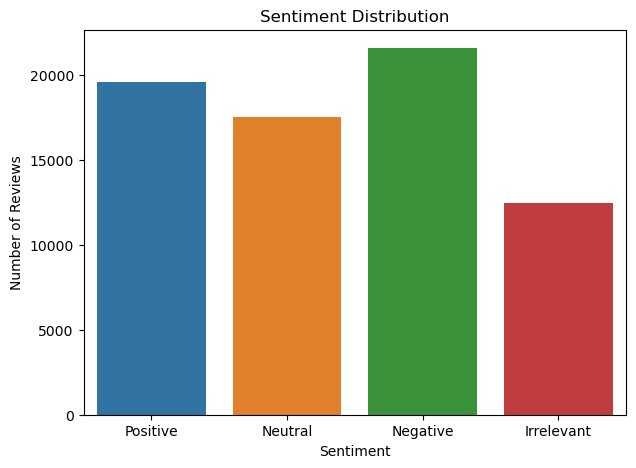

In [ ]:
# Sentiment Distribution
plt.figure(figsize=(7,5))

sns.countplot(data=df,x="Sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
#Sentiment percentage
print(df["Sentiment"].value_counts())

print("\nPercentage:")
print(df["Sentiment"].value_counts(normalize=True) * 100)

Negative      21579
Positive      19561
Neutral       17542
Irrelevant    12450
Name: Sentiment, dtype: int64

Percentage:
Negative      30.336557
Positive      27.499578
Neutral       24.661193
Irrelevant    17.502671
Name: Sentiment, dtype: float64


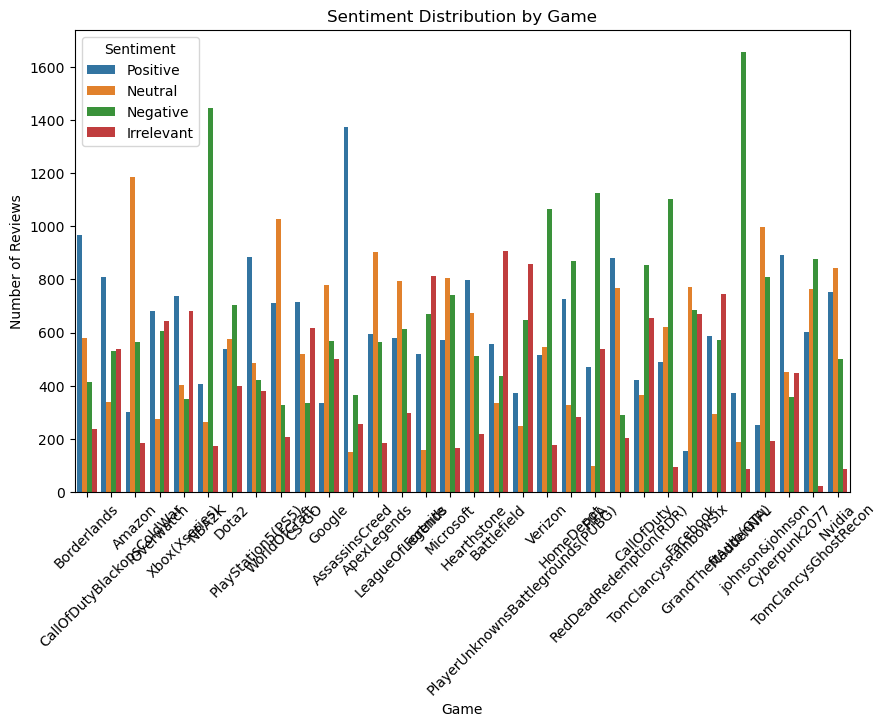

In [ ]:
# Sentiment Distriburion by Game
plt.figure(figsize=(10,6))

sns.countplot(data=df,x="Game",hue="Sentiment")

plt.title("Sentiment Distribution by Game")
plt.xlabel("Game")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=45)

plt.show()

In [29]:
#Text Length Distribution
df["Text_Length"] = df["Text"].astype(str).apply(len)

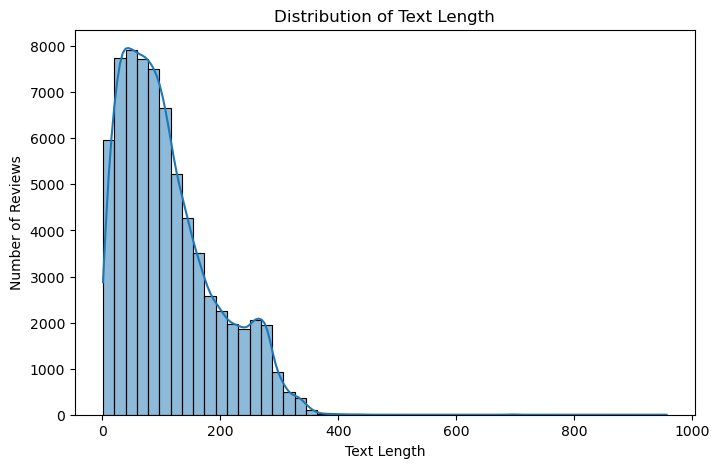

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(data=df,x="Text_Length",bins=50,kde=True)

plt.title("Distribution of Text Length")
plt.xlabel("Text Length")
plt.ylabel("Number of Reviews")

plt.show()

# Text Cleaning

In [36]:
def clean_text(text):

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove HTML
    text = re.sub(r"<.*?>", "", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [37]:
df["clean_text"] = df["Text"].apply(clean_text)

print(df[["Text", "clean_text"]].head())

                                                Text  \
0  I am coming to the borders and I will kill you...   
1  im getting on borderlands and i will kill you ...   
2  im coming on borderlands and i will murder you...   
3  im getting on borderlands 2 and i will murder ...   
4  im getting into borderlands and i can murder y...   

                                          clean_text  
0  i am coming to the borders and i will kill you...  
1  im getting on borderlands and i will kill you all  
2  im coming on borderlands and i will murder you...  
3  im getting on borderlands and i will murder yo...  
4  im getting into borderlands and i can murder y...  


In [38]:
# Original Text Clen Text Compare
for i in range(5):

    print("Original:")
    print(df["Text"].iloc[i])

    print("\nClean:")
    print(df["clean_text"].iloc[i])

    print("-" * 80)

Original:
I am coming to the borders and I will kill you all,

Clean:
i am coming to the borders and i will kill you all
--------------------------------------------------------------------------------
Original:
im getting on borderlands and i will kill you all,

Clean:
im getting on borderlands and i will kill you all
--------------------------------------------------------------------------------
Original:
im coming on borderlands and i will murder you all,

Clean:
im coming on borderlands and i will murder you all
--------------------------------------------------------------------------------
Original:
im getting on borderlands 2 and i will murder you me all,

Clean:
im getting on borderlands and i will murder you me all
--------------------------------------------------------------------------------
Original:
im getting into borderlands and i can murder you all,

Clean:
im getting into borderlands and i can murder you all
-----------------------------------------------------------

In [39]:
# Input Target 
X = df["clean_text"]
y = df["Sentiment"]

# Train Test 

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 56905
Testing samples: 14227


# Model Train

In [ ]:
#TF-IDF + Linear SVc
model = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            sublinear_tf=True,
            max_features=50000,
            ngram_range=(1, 2),   # Unigram + Bigram
            min_df=2,
            max_df=0.95
        )
    ),

    (
        "classifier",
        LinearSVC(C=1.0,max_iter=10000)   #svc
    )
])

In [48]:
#train
model.fit(X_train, y_train)

print("Model training completed")

Model training completed


In [49]:
#prediction
y_pred = model.predict(X_test)

In [ ]:
#accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)


Accuracy: 0.8866240247416883


In [66]:
# peremeter

In [62]:
pipeline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer()
    ),

    (
        "classifier",
        LinearSVC()
    )
])

In [63]:
parameters = {

    "tfidf__ngram_range": [
        (1,1),
        (1,2)
    ],

    "tfidf__min_df": [
        1,
        2,
        3
    ],

    "tfidf__max_df": [
        0.90,
        0.95,
        1.0
    ],

    "tfidf__sublinear_tf": [
        True
    ],

    "classifier__C": [
        0.5,
        1,
        2,
        3
    ]
}

In [65]:

grid = GridSearchCV(
    pipeline,
    parameters,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('tfidf', TfidfVectorizer()),
                                       ('classifier', LinearSVC())]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.5, 1, 2, 3],
                         'tfidf__max_df': [0.9, 0.95, 1.0],
                         'tfidf__min_df': [1, 2, 3],
                         'tfidf__ngram_range': [(1, 1), (1, 2)],
                         'tfidf__sublinear_tf': [True]},
             scoring='f1_macro', verbose=1)

In [68]:
print("Best Parameters:")
print(grid.best_params_)

Best Parameters:
{'classifier__C': 3, 'tfidf__max_df': 0.9, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}


In [69]:
best_model = grid.best_estimator_

In [70]:
y_pred_best = best_model.predict(X_test)

# Final Accuracy

In [71]:
final_accuracy = accuracy_score(
    y_test,
    y_pred_best
)

print("Final Accuracy:", final_accuracy)
print("Final Accuracy (%):", final_accuracy * 100)

Final Accuracy: 0.9304842904336824
Final Accuracy (%): 93.04842904336824


In [72]:
#Classification rport
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Irrelevant       0.91      0.84      0.87      2490
    Negative       0.90      0.91      0.91      4316
     Neutral       0.87      0.89      0.88      3509
    Positive       0.87      0.89      0.88      3912

    accuracy                           0.89     14227
   macro avg       0.89      0.88      0.88     14227
weighted avg       0.89      0.89      0.89     14227



# F1-Score


In [75]:
f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("F1 Score:", f1)
print("F1 Score (%):", f1 * 100)

F1 Score: 0.8842733787039302
F1 Score (%): 88.42733787039302


In [76]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Irrelevant       0.91      0.84      0.87      2490
    Negative       0.90      0.91      0.91      4316
     Neutral       0.87      0.89      0.88      3509
    Positive       0.87      0.89      0.88      3912

    accuracy                           0.89     14227
   macro avg       0.89      0.88      0.88     14227
weighted avg       0.89      0.89      0.89     14227



In [77]:
scoring="f1_macro"

In [78]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Accuracy:", accuracy * 100, "%")
print("Macro F1:", macro_f1)
print("Macro F1:", macro_f1 * 100, "%")

Accuracy: 88.66240247416883 %
Macro F1: 0.8842733787039302
Macro F1: 88.42733787039302 %


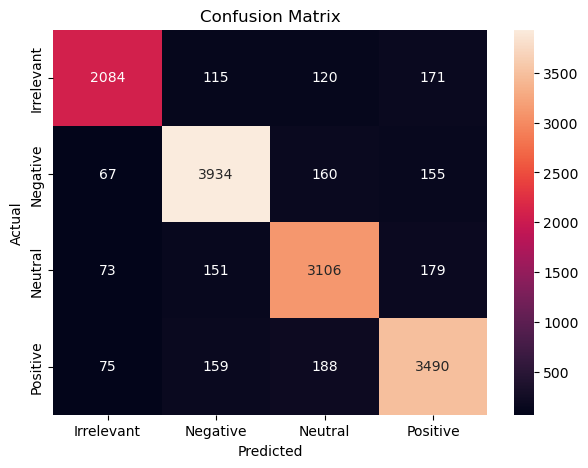

In [73]:
#Confution metrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()